In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/Project_WSN/WSN-DS.csv"

df = pd.read_csv(path)

In [ ]:
print("Shape:", df.shape)

df.head()

Shape: (374661, 19)


,id,Time,Is_CH,who CH,Dist_To_CH,ADV_S,ADV_R,JOIN_S,JOIN_R,SCH_S,SCH_R,Rank,DATA_S,DATA_R,Data_Sent_To_BS,dist_CH_To_BS,send_code,Expaned Energy,Attack type
0,101000,50,1,101000,0.00000,1,0,0,25,1,0,0,0,1200,48,130.08535,0,2.46940,Normal
1,101001,50,0,101044,75.32345,0,4,1,0,0,1,2,38,0,0,0.00000,4,0.06957,Normal
2,101002,50,0,101010,46.95453,0,4,1,0,0,1,19,41,0,0,0.00000,3,0.06898,Normal
3,101003,50,0,101044,64.85231,0,4,1,0,0,1,16,38,0,0,0.00000,4,0.06673,Normal
4,101004,50,0,101010,4.83341,0,4,1,0,0,1,25,41,0,0,0.00000,3,0.06534,Normal


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374661 entries, 0 to 374660
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0    id               374661 non-null  int64  
 1    Time             374661 non-null  int64  
 2    Is_CH            374661 non-null  int64  
 3    who CH           374661 non-null  int64  
 4    Dist_To_CH       374661 non-null  float64
 5    ADV_S            374661 non-null  int64  
 6    ADV_R            374661 non-null  int64  
 7    JOIN_S           374661 non-null  int64  
 8    JOIN_R           374661 non-null  int64  
 9    SCH_S            374661 non-null  int64  
 10   SCH_R            374661 non-null  int64  
 11  Rank              374661 non-null  int64  
 12   DATA_S           374661 non-null  int64  
 13   DATA_R           374661 non-null  int64  
 14   Data_Sent_To_BS  374661 non-null  int64  
 15   dist_CH_To_BS    374661 non-null  float64
 16   send_code        37

In [ ]:
df.isnull().sum()

,0
id,0
Time,0
Is_CH,0
who CH,0
Dist_To_CH,0
ADV_S,0
ADV_R,0
JOIN_S,0
JOIN_R,0
SCH_S,0


In [ ]:
print(df["Attack type"].value_counts())

Attack type
Normal       340066
Grayhole      14596
Blackhole     10049
TDMA           6638
Flooding       3312
Name: count, dtype: int64


In [ ]:
print(
    df["Attack type"]
    .value_counts(normalize=True)*100
)

Attack type
Normal       90.766319
Grayhole      3.895788
Blackhole     2.682158
TDMA          1.771735
Flooding      0.883999
Name: proportion, dtype: float64


In [ ]:
print(df.columns.tolist())

[' id', ' Time', ' Is_CH', ' who CH', ' Dist_To_CH', ' ADV_S', ' ADV_R', ' JOIN_S', ' JOIN_R', ' SCH_S', ' SCH_R', 'Rank', ' DATA_S', ' DATA_R', ' Data_Sent_To_BS', ' dist_CH_To_BS', ' send_code ', 'Expaned Energy', 'Attack type']


In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
print(df.columns.tolist())

['id', 'Time', 'Is_CH', 'who CH', 'Dist_To_CH', 'ADV_S', 'ADV_R', 'JOIN_S', 'JOIN_R', 'SCH_S', 'SCH_R', 'Rank', 'DATA_S', 'DATA_R', 'Data_Sent_To_BS', 'dist_CH_To_BS', 'send_code', 'Expaned Energy', 'Attack type']


In [ ]:
X = df.drop(columns=['id', 'Attack type'])

y = df['Attack type']

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [ ]:
print(dict(zip(le.classes_, range(len(le.classes_)))))

{'Blackhole': 0, 'Flooding': 1, 'Grayhole': 2, 'Normal': 3, 'TDMA': 4}


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (299728, 17)
X_test : (74933, 17)
y_train: (299728,)
y_test : (74933,)


In [ ]:
!pip install memory-profiler

In [ ]:
import time
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from memory_profiler import memory_usage

In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    start_memory = memory_usage()[0]

    start_train = time.time()

    model.fit(X_train, y_train)

    end_train = time.time()

    end_memory = memory_usage()[0]

    train_time = end_train - start_train

    memory_used = end_memory - start_memory

    start_pred = time.time()

    y_pred = model.predict(X_test)

    end_pred = time.time()

    prediction_time = end_pred - start_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average='weighted'
    )

    recall = recall_score(
        y_test,
        y_pred,
        average='weighted'
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average='weighted'
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Train Time (s)": train_time,
        "Prediction Time (s)": prediction_time,
        "Memory Used (MB)": memory_used
    }

**LR**

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [ ]:
lr_results = evaluate_model(
    lr,
    X_train,
    X_test,
    y_train,
    y_test
)

print(lr_results)

{'Accuracy': 0.9343146544246194, 'Precision': 0.92549646586147, 'Recall': 0.9343146544246194, 'F1': 0.9288180690876536, 'Train Time (s)': 116.67338371276855, 'Prediction Time (s)': 0.008074760437011719, 'Memory Used (MB)': 67.921875}


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.metrics import classification_report

y_pred_lr = lr.predict(X_test)

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.71      0.47      0.57      2010
           1       0.10      0.04      0.05       662
           2       0.48      0.49      0.49      2919
           3       0.97      0.99      0.98     68014
           4       0.59      0.43      0.50      1328

    accuracy                           0.93     74933
   macro avg       0.57      0.48      0.52     74933
weighted avg       0.93      0.93      0.93     74933



In [ ]:
results = []

lr_results["Model"] = "Logistic Regression"

results.append(lr_results)

**DT**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(
    random_state=42
)

In [ ]:
dt_results = evaluate_model(
    dt,
    X_train,
    X_test,
    y_train,
    y_test
)

print(dt_results)

{'Accuracy': 0.9947419694927468, 'Precision': 0.9947754158215155, 'Recall': 0.9947419694927468, 'F1': 0.9947562901242109, 'Train Time (s)': 1.9640955924987793, 'Prediction Time (s)': 0.00814962387084961, 'Memory Used (MB)': 8.5546875}


In [ ]:
from sklearn.metrics import classification_report

y_pred_dt = dt.predict(X_test)

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2010
           1       0.95      0.94      0.94       662
           2       0.98      0.98      0.98      2919
           3       1.00      1.00      1.00     68014
           4       0.91      0.94      0.92      1328

    accuracy                           0.99     74933
   macro avg       0.97      0.97      0.97     74933
weighted avg       0.99      0.99      0.99     74933



In [ ]:
dt_results["Model"] = "Decision Tree"

results.append(dt_results)

**RF**

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_results = evaluate_model(
    rf,
    X_train,
    X_test,
    y_train,
    y_test
)

print(rf_results)

{'Accuracy': 0.9971574606648607, 'Precision': 0.997184162570295, 'Recall': 0.9971574606648607, 'F1': 0.9971457189512622, 'Train Time (s)': 26.170514822006226, 'Prediction Time (s)': 0.5275733470916748, 'Memory Used (MB)': 85.92578125}


In [ ]:
from sklearn.metrics import classification_report

y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      2010
           1       0.94      0.99      0.97       662
           2       0.99      0.99      0.99      2919
           3       1.00      1.00      1.00     68014
           4       0.99      0.93      0.96      1328

    accuracy                           1.00     74933
   macro avg       0.98      0.98      0.98     74933
weighted avg       1.00      1.00      1.00     74933



In [ ]:
rf_results["Model"] = "Random Forest"
results.append(rf_results)

**XG BOOST**

In [ ]:
!pip install xgboost
from xgboost import XGBClassifier

In [ ]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective='multi:softmax',
    num_class=5,
    random_state=42
)

In [ ]:
xgb_results = evaluate_model(
    xgb,
    X_train,
    X_test,
    y_train,
    y_test
)

print(xgb_results)

{'Accuracy': 0.9966770314814568, 'Precision': 0.9967148787637459, 'Recall': 0.9966770314814568, 'F1': 0.9966650177914157, 'Train Time (s)': 18.458695650100708, 'Prediction Time (s)': 0.39299464225769043, 'Memory Used (MB)': 18.546875}


In [ ]:
y_pred_xgb = xgb.predict(X_test)

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_xgb
    )
)

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2010
           1       0.93      0.99      0.96       662
           2       0.99      0.98      0.98      2919
           3       1.00      1.00      1.00     68014
           4       1.00      0.93      0.96      1328

    accuracy                           1.00     74933
   macro avg       0.98      0.98      0.98     74933
weighted avg       1.00      1.00      1.00     74933



In [ ]:
xgb_results["Model"] = "XGBoost"

results.append(xgb_results)

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Train Time (s)",
        "Prediction Time (s)",
        "Memory Used (MB)"
    ]
]

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,Train Time (s),Prediction Time (s),Memory Used (MB)
2,Random Forest,0.997157,0.997184,0.997157,0.997146,26.170515,0.527573,85.925781
3,XGBoost,0.996677,0.996715,0.996677,0.996665,18.458696,0.392995,18.546875
1,Decision Tree,0.994742,0.994775,0.994742,0.994756,1.964096,0.008150,8.554688
0,Logistic Regression,0.934315,0.925496,0.934315,0.928818,116.673384,0.008075,67.921875


In [ ]:
results_df

,Model,Accuracy,Precision,Recall,F1,Train Time (s),Prediction Time (s),Memory Used (MB)
0,Logistic Regression,0.934315,0.925496,0.934315,0.928818,116.673384,0.008075,67.921875
1,Decision Tree,0.994742,0.994775,0.994742,0.994756,1.964096,0.008150,8.554688
2,Random Forest,0.997157,0.997184,0.997157,0.997146,26.170515,0.527573,85.925781
3,XGBoost,0.996677,0.996715,0.996677,0.996665,18.458696,0.392995,18.546875


In [ ]:
results_df.to_csv("baseline_model_results.csv", index=False)

In [ ]:
from google.colab import files

files.download("baseline_model_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Feature** **selection**

In [ ]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

            Feature  Importance
1             Is_CH    0.152718
4             ADV_S    0.151761
16   Expaned Energy    0.141259
13  Data_Sent_To_BS    0.116760
8             SCH_S    0.075000
11           DATA_S    0.059743
5             ADV_R    0.037184
14    dist_CH_To_BS    0.036290
10             Rank    0.036236
7            JOIN_R    0.034819
2            who CH    0.032096
12           DATA_R    0.031913
0              Time    0.026538
3        Dist_To_CH    0.026093
6            JOIN_S    0.021213
15        send_code    0.015716
9             SCH_R    0.004662


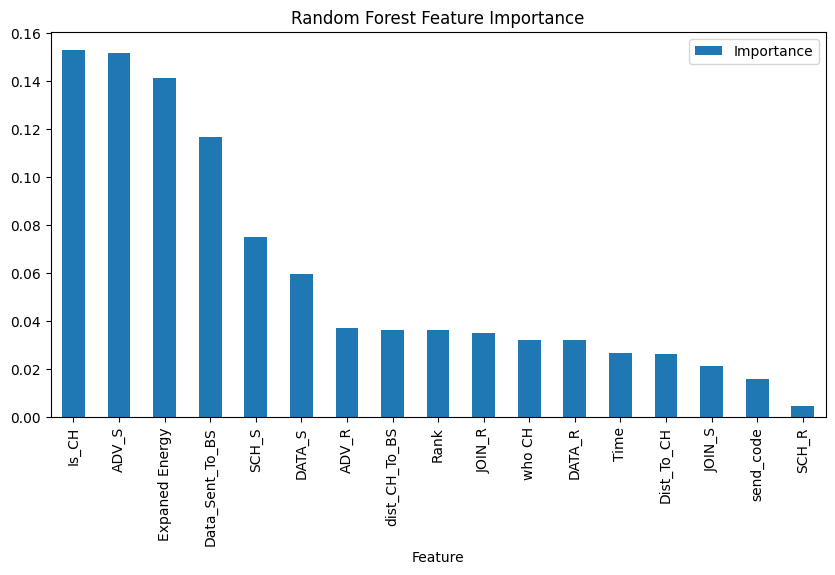

In [ ]:
import matplotlib.pyplot as plt

feature_importance.plot(
    x='Feature',
    y='Importance',
    kind='bar',
    figsize=(10,5)
)

plt.title("Random Forest Feature Importance")
plt.show()

In [ ]:
top10_features = [
    'Is_CH',
    'ADV_S',
    'Expaned Energy',
    'Data_Sent_To_BS',
    'SCH_S',
    'DATA_S',
    'ADV_R',
    'dist_CH_To_BS',
    'Rank',
    'JOIN_R'
]

top5_features = [
    'Is_CH',
    'ADV_S',
    'Expaned Energy',
    'Data_Sent_To_BS',
    'SCH_S'
]

X_top10 = X[top10_features]

X_top5 = X[top5_features]

In [ ]:
from sklearn.model_selection import train_test_split

X10_train, X10_test, y10_train, y10_test = train_test_split(
    X_top10,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X_top5,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

**Dt with 10**

In [ ]:
dt_top10 = DecisionTreeClassifier(random_state=42)

dt10_results = evaluate_model(
    dt_top10,
    X10_train,
    X10_test,
    y10_train,
    y10_test
)

print(dt10_results)

{'Accuracy': 0.9940613614829248, 'Precision': 0.9940986352860055, 'Recall': 0.9940613614829248, 'F1': 0.9940775342393142, 'Train Time (s)': 0.9950840473175049, 'Prediction Time (s)': 0.009935379028320312, 'Memory Used (MB)': 34.30078125}


In [ ]:
dt10_results["Model"] = "DT_Top10"
results.append(dt10_results)

**Rf with 10**

In [ ]:
rf_top10 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf10_results = evaluate_model(
    rf_top10,
    X10_train,
    X10_test,
    y10_train,
    y10_test
)

print(rf10_results)

{'Accuracy': 0.9958629709206891, 'Precision': 0.9959037533651368, 'Recall': 0.9958629709206891, 'F1': 0.9958585449261895, 'Train Time (s)': 30.581308364868164, 'Prediction Time (s)': 0.4777827262878418, 'Memory Used (MB)': 95.25}


In [ ]:
rf10_results["Model"] = "RF_Top10"
results.append(rf10_results)

**Dt top 5**

In [ ]:
dt_top5 = DecisionTreeClassifier(random_state=42)

dt5_results = evaluate_model(
    dt_top5,
    X5_train,
    X5_test,
    y5_train,
    y5_test
)

print(dt5_results)

{'Accuracy': 0.9909118812806107, 'Precision': 0.9908549937108003, 'Recall': 0.9909118812806107, 'F1': 0.9908640488858328, 'Train Time (s)': 2.0720155239105225, 'Prediction Time (s)': 0.03138566017150879, 'Memory Used (MB)': 0.0}


In [ ]:
dt5_results["Model"] = "DT_Top5"
results.append(dt5_results)

**RF top 5**

In [ ]:
rf_top5 = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf5_results = evaluate_model(
    rf_top5,
    X5_train,
    X5_test,
    y5_train,
    y5_test
)

print(rf5_results)

{'Accuracy': 0.9917926681168511, 'Precision': 0.9917714429157223, 'Recall': 0.9917926681168511, 'F1': 0.991754828222197, 'Train Time (s)': 49.241069078445435, 'Prediction Time (s)': 0.46700501441955566, 'Memory Used (MB)': 37.3046875}


In [ ]:
rf5_results["Model"] = "RF_Top5"
results.append(rf5_results)

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Accuracy,Precision,Recall,F1,Train Time (s),Prediction Time (s),Memory Used (MB),Model
2,0.997157,0.997184,0.997157,0.997146,26.170515,0.527573,85.925781,Random Forest
3,0.996677,0.996715,0.996677,0.996665,18.458696,0.392995,18.546875,XGBoost
5,0.995863,0.995904,0.995863,0.995859,30.581308,0.477783,95.250000,RF_Top10
1,0.994742,0.994775,0.994742,0.994756,1.964096,0.008150,8.554688,Decision Tree
4,0.994061,0.994099,0.994061,0.994078,0.995084,0.009935,34.300781,DT_Top10
7,0.991793,0.991771,0.991793,0.991755,49.241069,0.467005,37.304688,RF_Top5
6,0.990912,0.990855,0.990912,0.990864,2.072016,0.031386,0.000000,DT_Top5
0,0.934315,0.925496,0.934315,0.928818,116.673384,0.008075,67.921875,Logistic Regression


**confusion matrix**

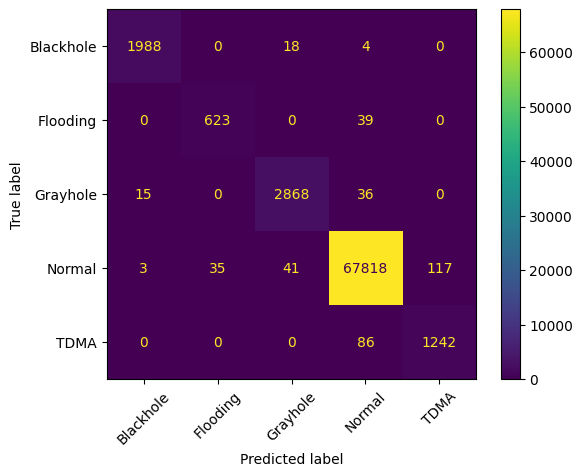

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    dt,
    X_test,
    y_test,
    display_labels=le.classes_,
    xticks_rotation=45
)

plt.show()

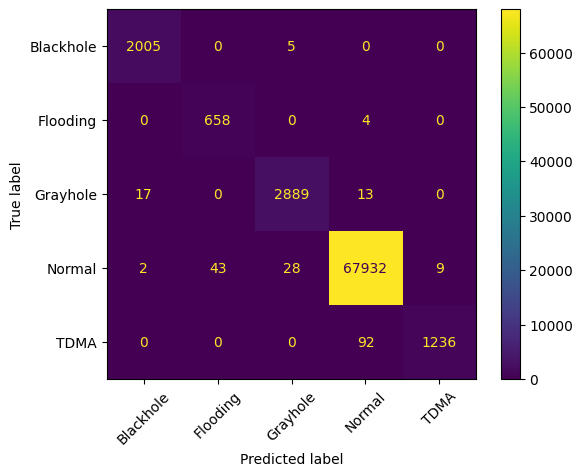

In [ ]:
ConfusionMatrixDisplay.from_estimator(
    rf,
    X_test,
    y_test,
    display_labels=le.classes_,
    xticks_rotation=45
)

plt.show()

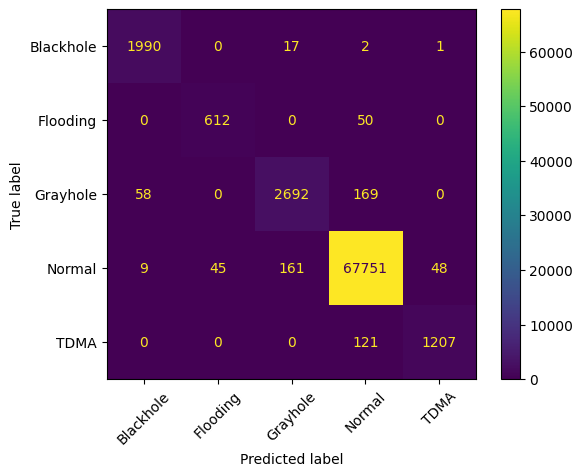

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    dt_top5,
    X5_test,
    y5_test,
    display_labels=le.classes_,
    xticks_rotation=45
)

plt.show()

**Accuracy Comparison**

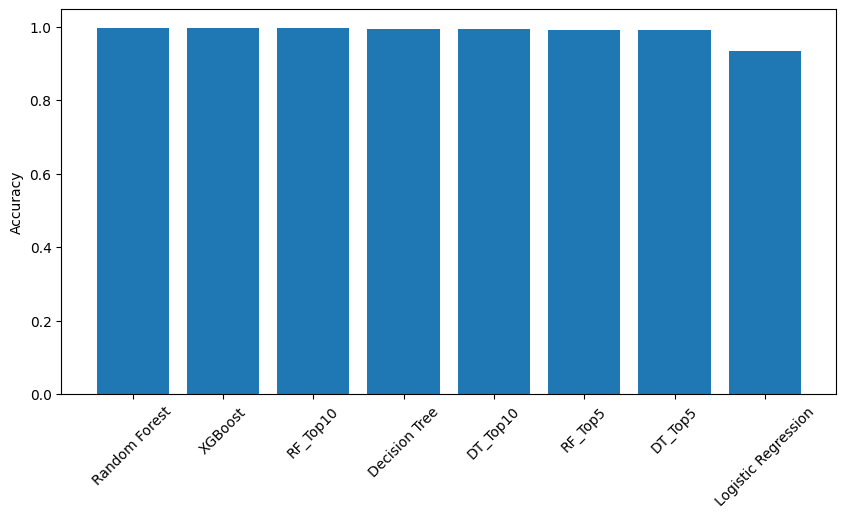

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.xticks(rotation=45)

plt.ylabel("Accuracy")

plt.show()

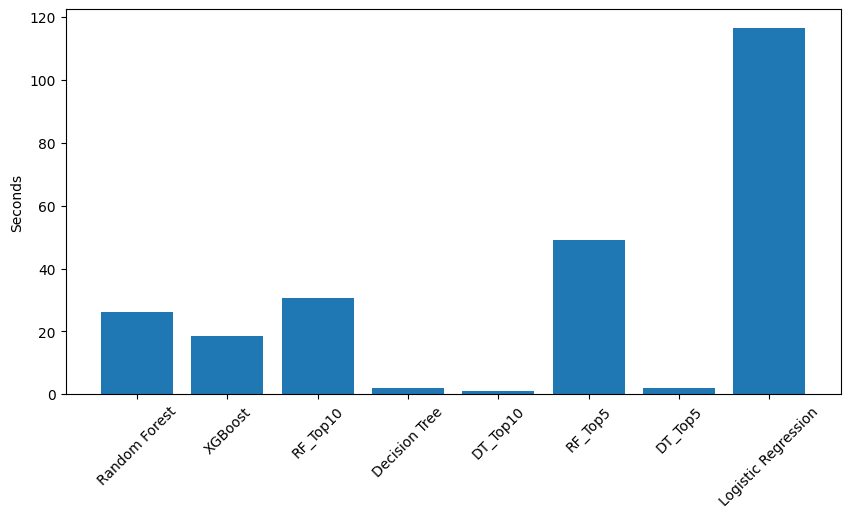

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(results_df["Model"], results_df["Train Time (s)"])

plt.xticks(rotation=45)

plt.ylabel("Seconds")

plt.show()

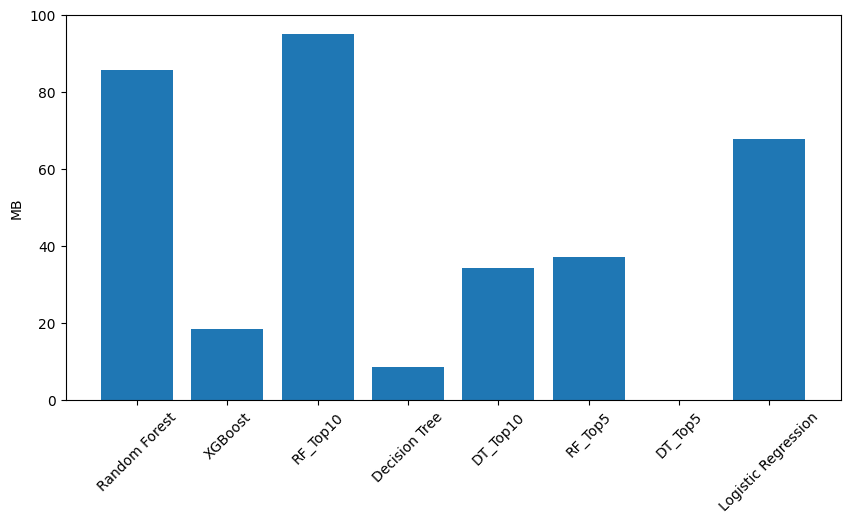

In [ ]:
plt.figure(figsize=(10,5))

plt.bar(results_df["Model"], results_df["Memory Used (MB)"])

plt.xticks(rotation=45)

plt.ylabel("MB")

plt.show()

**Model Selection**

In [ ]:
import joblib

# Full Decision Tree (17 features)
joblib.dump(dt, "dt_full_17_features.pkl")

# Lightweight Decision Tree (Top 5 features)
joblib.dump(dt_top5, "dt_lightweight_top5.pkl")

# Label Encoder
joblib.dump(le, "label_encoder.pkl")

# Top 5 Feature List
top5_features = [
    'Is_CH',
    'ADV_S',
    'Expaned Energy',
    'Data_Sent_To_BS',
    'SCH_S'
]

joblib.dump(top5_features, "top5_features.pkl")

print("All files saved successfully!")

All files saved successfully!


In [ ]:
from google.colab import files

files.download("dt_full_17_features.pkl")
files.download("dt_lightweight_top5.pkl")
files.download("label_encoder.pkl")
files.download("top5_features.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

save_path = "/content/drive/MyDrive/WSN_Project_Models"
os.makedirs(save_path, exist_ok=True)

In [ ]:
import joblib

# Full Decision Tree
joblib.dump(
    dt,
    "/content/drive/MyDrive/WSN_Project_Models/dt_full_17_features.pkl"
)

# Lightweight Decision Tree
joblib.dump(
    dt_top5,
    "/content/drive/MyDrive/WSN_Project_Models/dt_lightweight_top5.pkl"
)

# Label Encoder
joblib.dump(
    le,
    "/content/drive/MyDrive/WSN_Project_Models/label_encoder.pkl"
)

# Top 5 Features
top5_features = [
    'Is_CH',
    'ADV_S',
    'Expaned Energy',
    'Data_Sent_To_BS',
    'SCH_S'
]

joblib.dump(
    top5_features,
    "/content/drive/MyDrive/WSN_Project_Models/top5_features.pkl"
)

print("Saved successfully to Google Drive!")

Saved successfully to Google Drive!


In [ ]:
results_df.to_csv(
    "/content/drive/MyDrive/WSN_Project_Models/model_comparison_results.csv",
    index=False
)

**pca**

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

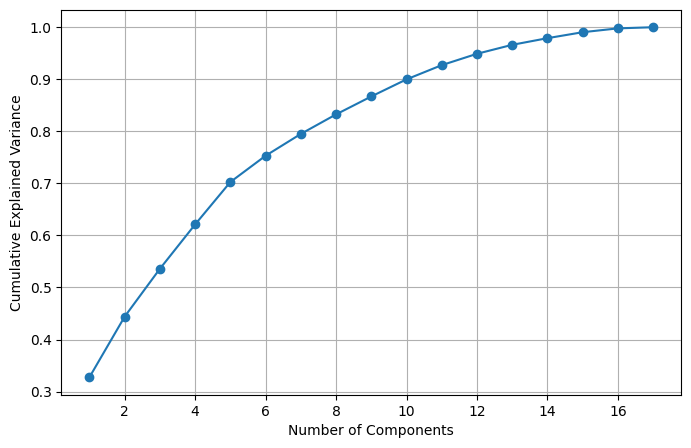

In [ ]:
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

pca = PCA()
pca.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8,5))
plt.plot(
    range(1, len(cumulative_variance)+1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.grid(True)
plt.show()

In [ ]:
for i, var in enumerate(cumulative_variance):
    print(
        f"Components: {i+1}, Variance Explained: {var:.4f}"
    )

Components: 1, Variance Explained: 0.3276
Components: 2, Variance Explained: 0.4441
Components: 3, Variance Explained: 0.5360
Components: 4, Variance Explained: 0.6212
Components: 5, Variance Explained: 0.7026
Components: 6, Variance Explained: 0.7531
Components: 7, Variance Explained: 0.7950
Components: 8, Variance Explained: 0.8325
Components: 9, Variance Explained: 0.8670
Components: 10, Variance Explained: 0.8998
Components: 11, Variance Explained: 0.9271
Components: 12, Variance Explained: 0.9489
Components: 13, Variance Explained: 0.9662
Components: 14, Variance Explained: 0.9790
Components: 15, Variance Explained: 0.9904
Components: 16, Variance Explained: 0.9978
Components: 17, Variance Explained: 1.0000


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=13)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(374661, 13)


In [ ]:
from sklearn.model_selection import train_test_split

Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_pca,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_pca = DecisionTreeClassifier(
    random_state=42
)

dt_pca_results = evaluate_model(
    dt_pca,
    Xp_train,
    Xp_test,
    yp_train,
    yp_test
)

print(dt_pca_results)

{'Accuracy': 0.9933807534731026, 'Precision': 0.9933897585694311, 'Recall': 0.9933807534731026, 'F1': 0.9933813142045989, 'Train Time (s)': 31.151324033737183, 'Prediction Time (s)': 0.01169896125793457, 'Memory Used (MB)': 24.59765625}


In [ ]:
from sklearn.metrics import classification_report

y_pred_pca = dt_pca.predict(Xp_test)

print(
    classification_report(
        yp_test,
        y_pred_pca,
        target_names=le.classes_
    )
)

              precision    recall  f1-score   support

   Blackhole       0.98      0.99      0.98      2010
    Flooding       0.94      0.91      0.93       662
    Grayhole       0.97      0.97      0.97      2919
      Normal       1.00      1.00      1.00     68014
        TDMA       0.90      0.92      0.91      1328

    accuracy                           0.99     74933
   macro avg       0.96      0.96      0.96     74933
weighted avg       0.99      0.99      0.99     74933



In [ ]:
dt_pca_results["Model"] = "DT_PCA_13"

results.append(dt_pca_results)

In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="Accuracy",
    ascending=False
)

,Accuracy,Precision,Recall,F1,Train Time (s),Prediction Time (s),Memory Used (MB),Model
2,0.997157,0.997184,0.997157,0.997146,26.170515,0.527573,85.925781,Random Forest
3,0.996677,0.996715,0.996677,0.996665,18.458696,0.392995,18.546875,XGBoost
5,0.995863,0.995904,0.995863,0.995859,30.581308,0.477783,95.250000,RF_Top10
1,0.994742,0.994775,0.994742,0.994756,1.964096,0.008150,8.554688,Decision Tree
4,0.994061,0.994099,0.994061,0.994078,0.995084,0.009935,34.300781,DT_Top10
8,0.993381,0.993390,0.993381,0.993381,31.151324,0.011699,24.597656,DT_PCA_13
7,0.991793,0.991771,0.991793,0.991755,49.241069,0.467005,37.304688,RF_Top5
6,0.990912,0.990855,0.990912,0.990864,2.072016,0.031386,0.000000,DT_Top5
0,0.934315,0.925496,0.934315,0.928818,116.673384,0.008075,67.921875,Logistic Regression


In [ ]:
import joblib

joblib.dump(dt_pca, "dt_pca_13.pkl")
joblib.dump(pca, "pca_transformer.pkl")
joblib.dump(scaler, "standard_scaler.pkl")

['standard_scaler.pkl']

In [ ]:
save_path = "/content/drive/MyDrive/WSN_Project_Models"
os.makedirs(save_path, exist_ok=True)

# PCA Decision Tree Model
joblib.dump(
    dt_pca,
    f"{save_path}/dt_pca_13.pkl"
)

# PCA Transformer
joblib.dump(
    pca,
    f"{save_path}/pca_transformer.pkl"
)

# Standard Scaler
joblib.dump(
    scaler,
    f"{save_path}/standard_scaler.pkl"
)

print("All PCA files saved to Google Drive successfully!")

All PCA files saved to Google Drive successfully!


In [ ]:
import sys
import sklearn
import numpy
import pandas

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
Scikit-learn: 1.6.1
NumPy: 2.1.3
Pandas: 2.2.3
